# ACA N.º 2 — Aprendizaje Automático aplicado a Ventas
**CUN · Especialización en Inteligencia Artificial · Asignatura: Aprendizaje Automático**
**Docente:** Hamilton Rivera Flor

**Integrantes:** _completar antes de entregar_

## Objetivo general
Desarrollar, entrenar, evaluar y desplegar **tres arquitecturas de redes neuronales artificiales**
— convolucional (CNN), recurrente secuencial (LSTM+GRU) y basada en atención (Transformer) —
que pronostiquen las ventas diarias de una tienda minorista a partir de `train.csv`,
integrando preprocesamiento, gestión SQL, entrenamiento, evaluación comparativa y despliegue
funcional en una interfaz interactiva con **Streamlit**, accesible mediante una URL pública (ngrok).

## Pregunta orientadora
¿En qué medida distintas arquitecturas de redes neuronales (CNN, RNN secuencial y Transformer)
logran aprender patrones temporales en transacciones comerciales para anticipar las ventas del
día siguiente, y cuál ofrece el mejor desempeño?

## Modalidad y justificación de las tres arquitecturas
Los datos son **tabulares transformados en serie temporal** (no hay texto ni imágenes), por lo que
no se aplica tokenización lingüística; la ingeniería de secuencias (ventanas deslizantes) es el
equivalente pertinente exigido por el PASO 2 de la ruta metodológica del ACA N.º 2.

| Arquitectura | Por qué aplica a series de ventas |
|---|---|
| **CNN (Conv1D)** | Detecta patrones locales de corto plazo (picos semanales, rachas). |
| **Secuencial (LSTM + GRU)** | Modela dependencias de memoria a mediano/largo plazo (estacionalidad). |
| **Transformer** | Auto-atención multi-cabeza para ponderar qué días de la ventana importan más. |

> **Este notebook es autocontenido**: la primera celda de código crea `pipeline.py`, `poster.py`
> y `app.py` directamente en el disco (no requiere subir esos archivos por separado). Solo
> necesita tener `train.csv` en la misma carpeta donde ejecuta el notebook (por ejemplo, en
> Google Colab: `/content/train.csv`).


## Preparación del entorno — crea `pipeline.py`, `poster.py` y `app.py`
Ejecute esta celda primero. Escribe en disco, de forma exacta y completa, los tres archivos de
código que usa el resto del notebook y la app Streamlit. No necesita subir ningún archivo `.py`
por separado: solo `train.csv` debe estar presente en la carpeta de trabajo.

In [18]:
%%writefile pipeline.py
"""
ACA N.2 - Aprendizaje Automatico (CUN) | Pilar: Ventas
Pipeline unico que entrena y evalua TRES arquitecturas de redes neuronales
profundas sobre la misma serie de ventas diarias (Sales Forecasting - Retail
Superstore / train.csv):

    1) CNN   -> Conv1DForecast        (red neuronal convolucional 1D)
    2) RNN   -> SecuencialForecast    (red secuencial recurrente LSTM+GRU)
    3) TRF   -> TransformerForecast   (arquitectura basada en atencion)

El resto del flujo (lectura de datos, EDA, SQL, ventanas deslizantes,
normalizacion, aumento de datos, metricas y persistencia) se reutiliza de
forma identica para las tres arquitecturas, de modo que la comparacion sea
justa y reproducible.
"""
from __future__ import annotations
from pathlib import Path
import json
import random
import sqlite3

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

WINDOW = 28          # dias de contexto usados para predecir el dia siguiente
SEED = 42
MODELOS = ["cnn", "rnn", "transformer"]
NOMBRES_MODELOS = {
    "cnn": "CNN (Conv1D)",
    "rnn": "Secuencial (LSTM+GRU)",
    "transformer": "Transformer (atencion)",
}


def seed_all(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# --------------------------------------------------------------------------
# PASO 1: Exploracion y gestion de datos (EDA + SQL)
# --------------------------------------------------------------------------
def read_sales(path: str = "train.csv") -> pd.DataFrame:
    candidatos = [Path(path), Path("datos") / path, Path("datos/train.csv")]
    archivo = next((p for p in candidatos if p.exists()), None)
    if archivo is None:
        raise FileNotFoundError(f"No se encontro el dataset en: {candidatos}")
    df = pd.read_csv(archivo, encoding="latin-1")
    for col in ("Order Date", "Ship Date"):
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], format="%d/%m/%Y", errors="coerce")
            if df[col].isna().mean() > 0.5:
                df[col] = pd.to_datetime(df[col], errors="coerce")
    return df


def daily_sales(df: pd.DataFrame) -> pd.DataFrame:
    serie = df.groupby("Order Date")["Sales"].sum().rename("sales")
    rango = pd.date_range(serie.index.min(), serie.index.max(), freq="D")
    daily = serie.reindex(rango, fill_value=0.0).rename_axis("date").reset_index()
    daily["weekday"] = daily["date"].dt.weekday
    daily["month"] = daily["date"].dt.month
    return daily


def sql_databases(df: pd.DataFrame, daily: pd.DataFrame, carpeta: str = "bases_sql") -> dict:
    """Crea tres bases SQLite independientes: transacciones, analitica y predicciones."""
    Path(carpeta).mkdir(exist_ok=True)
    rutas = {
        "transacciones": str(Path(carpeta) / "transacciones.sqlite"),
        "analitica": str(Path(carpeta) / "analitica.sqlite"),
        "predicciones": str(Path(carpeta) / "predicciones.sqlite"),
    }

    cols = ["Row ID", "Order ID", "Order Date", "Customer Name", "Segment",
            "Region", "Category", "Sub-Category", "Product Name", "Sales"]
    tx = df[[c for c in cols if c in df.columns]].copy()
    tx.columns = [c.lower().replace(" ", "_").replace("-", "_") for c in tx.columns]
    with sqlite3.connect(rutas["transacciones"]) as conn:
        tx.to_sql("ventas", conn, if_exists="replace", index=False)

    mensual = (daily.assign(periodo=daily["date"].dt.to_period("M").astype(str))
               .groupby("periodo")["sales"].sum().rename("ventas").reset_index())
    with sqlite3.connect(rutas["analitica"]) as conn:
        daily.rename(columns={"sales": "ventas"}).to_sql(
            "ventas_diarias", conn, if_exists="replace", index=False)
        mensual.to_sql("ventas_mensuales", conn, if_exists="replace", index=False)

    with sqlite3.connect(rutas["predicciones"]) as conn:
        conn.execute("""CREATE TABLE IF NOT EXISTS predicciones (
            modelo TEXT, particion TEXT, fecha TEXT, real REAL, prediccion REAL)""")
        conn.commit()
    return rutas


def guardar_predicciones_sql(pred: pd.DataFrame, modelo: str, ruta_db: str) -> None:
    out = pred.copy()
    out["modelo"] = modelo
    with sqlite3.connect(ruta_db) as conn:
        out[["modelo", "particion", "fecha", "real", "prediccion"]].to_sql(
            "predicciones", conn, if_exists="append", index=False)


# --------------------------------------------------------------------------
# PASO 2: Preparacion, pipeline y aumento de datos (ingenieria de secuencias)
# --------------------------------------------------------------------------
def prepare(daily: pd.DataFrame, window: int = WINDOW) -> dict:
    n = len(daily)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    scaler = StandardScaler()
    scaler.fit(daily["sales"].values[:train_end].reshape(-1, 1))
    valores_norm = scaler.transform(daily["sales"].values.reshape(-1, 1)).flatten()

    X, y, fechas = [], [], []
    for i in range(window, n):
        X.append(valores_norm[i - window:i])
        y.append(valores_norm[i])
        fechas.append(daily["date"].iloc[i])
    X = np.array(X, dtype=np.float32)[..., None]   # (muestras, ventana, 1 variable)
    y = np.array(y, dtype=np.float32)
    fechas = pd.to_datetime(fechas)

    masks = {
        "train": fechas < daily["date"].iloc[train_end],
        "val": (fechas >= daily["date"].iloc[train_end]) & (fechas < daily["date"].iloc[val_end]),
        "test": fechas >= daily["date"].iloc[val_end],
    }
    limits = {
        "train_end": str(daily["date"].iloc[train_end - 1].date()),
        "val_end": str(daily["date"].iloc[val_end - 1].date()),
        "test_end": str(daily["date"].iloc[-1].date()),
    }
    return {"X": X, "y": y, "fechas": fechas, "masks": masks,
            "scaler": scaler, "limits": limits, "daily": daily, "window": window}


def _augment(Xb: torch.Tensor, sigma: float = 0.015) -> torch.Tensor:
    return Xb + torch.randn_like(Xb) * sigma


# --------------------------------------------------------------------------
# PASO 3: Arquitecturas de redes neuronales
# --------------------------------------------------------------------------
class Conv1DForecast(nn.Module):
    """Red Neuronal Convolucional (CNN) 1D: extrae patrones locales en la
    ventana temporal mediante convoluciones apiladas con pooling."""

    def __init__(self, in_ch: int = 1, canales=(16, 32), kernel: int = 5):
        super().__init__()
        capas, c_in = [], in_ch
        for c_out in canales:
            capas += [nn.Conv1d(c_in, c_out, kernel, padding=kernel // 2),
                      nn.BatchNorm1d(c_out), nn.ReLU(), nn.Dropout(0.15)]
            c_in = c_out
        self.conv = nn.Sequential(*capas)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(nn.Linear(c_in, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):
        # x: (batch, ventana, variables) -> Conv1d espera (batch, canales, ventana)
        x = x.transpose(1, 2)
        x = self.conv(x)
        x = self.pool(x).squeeze(-1)
        return self.head(x).squeeze(-1)


class SecuencialForecast(nn.Module):
    """Red Neuronal Recurrente secuencial: LSTM seguida de GRU, la
    arquitectura originalmente planteada para el pilar de ventas."""

    def __init__(self, in_ch: int = 1, hidden: int = 32, dropout: float = 0.12):
        super().__init__()
        self.lstm = nn.LSTM(in_ch, hidden, num_layers=1, batch_first=True)
        self.gru = nn.GRU(hidden, hidden, num_layers=1, batch_first=True, dropout=0.0)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        out, h = self.gru(out)
        out = self.drop(h[-1])
        return self.head(out).squeeze(-1)


# Alias retrocompatible: el notebook original importaba GRUForecast.
GRUForecast = SecuencialForecast


class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 256):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class TransformerForecast(nn.Module):
    """Arquitectura basada en atencion (Transformer encoder): proyecta cada
    paso temporal a un espacio latente, agrega codificacion posicional y
    aplica auto-atencion multi-cabeza para pronosticar el dia siguiente."""

    def __init__(self, in_ch: int = 1, d_model: int = 32, nhead: int = 4,
                 num_layers: int = 2, dim_ff: int = 64, dropout: float = 0.1,
                 window: int = WINDOW):
        super().__init__()
        self.proyeccion = nn.Linear(in_ch, d_model)
        self.pos = PositionalEncoding(d_model, max_len=window + 1)
        capa = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=dropout, batch_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(capa, num_layers=num_layers)
        self.head = nn.Sequential(nn.Linear(d_model, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):
        z = self.proyeccion(x)
        z = self.pos(z)
        z = self.encoder(z)
        z = z.mean(dim=1)  # agregacion temporal (promedio de los estados atendidos)
        return self.head(z).squeeze(-1)


def construir_modelo(tipo: str, window: int = WINDOW) -> nn.Module:
    tipo = tipo.lower()
    if tipo == "cnn":
        return Conv1DForecast()
    if tipo in ("rnn", "secuencial"):
        return SecuencialForecast()
    if tipo in ("transformer", "trf", "atencion"):
        return TransformerForecast(window=window)
    raise ValueError(f"Tipo de modelo no reconocido: {tipo}")


# --------------------------------------------------------------------------
# Entrenamiento generico (valido para las 3 arquitecturas)
# --------------------------------------------------------------------------
def train_model(bundle: dict, tipo: str = "rnn", epochs: int = 35,
                 patience: int = 7, augment: bool = True, lr: float = 1e-3,
                 batch_size: int = 32, model: nn.Module | None = None):
    seed_all()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = (model or construir_modelo(tipo, window=bundle["window"])).to(device)

    X, y, masks = bundle["X"], bundle["y"], bundle["masks"]
    Xtr = torch.tensor(X[masks["train"]])
    ytr = torch.tensor(y[masks["train"]])
    Xval = torch.tensor(X[masks["val"]]).to(device)
    yval = torch.tensor(y[masks["val"]]).to(device)

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    loss_fn = nn.SmoothL1Loss()
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)

    mejor_val, espera, mejor_estado = float("inf"), 0, None
    historial = []
    n = Xtr.shape[0]
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n)
        perdida_ep = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = Xtr[idx].to(device), ytr[idx].to(device)
            if augment:
                xb = _augment(xb)
            opt.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            perdida_ep += loss.item() * len(idx)
        perdida_ep /= n

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xval), yval).item()
        sched.step(val_loss)
        historial.append({"epoch": epoch, "train_loss": perdida_ep, "val_loss": val_loss})

        if val_loss < mejor_val - 1e-5:
            mejor_val, espera = val_loss, 0
            mejor_estado = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            espera += 1
            if espera >= patience:
                break

    if mejor_estado is not None:
        model.load_state_dict(mejor_estado)
    return model, pd.DataFrame(historial)


# --------------------------------------------------------------------------
# PASO 4: Evaluacion y metricas
# --------------------------------------------------------------------------
def _smape(y_true, y_pred):
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    denom = np.where(denom == 0, 1e-8, denom)
    return float(np.mean(np.abs(y_true - y_pred) / denom) * 100)


def evaluate(model: nn.Module, bundle: dict) -> tuple[dict, pd.DataFrame, float]:
    device = next(model.parameters()).device
    model.eval()
    scaler = bundle["scaler"]
    X, y, fechas, masks = bundle["X"], bundle["y"], bundle["fechas"], bundle["masks"]

    with torch.no_grad():
        pred_norm_all = model(torch.tensor(X).to(device)).cpu().numpy()

    real_all = scaler.inverse_transform(y.reshape(-1, 1)).flatten()
    pred_all = scaler.inverse_transform(pred_norm_all.reshape(-1, 1)).flatten()

    umbral = float(np.percentile(real_all[masks["train"]], 75))

    registros, metrics = [], {}
    for particion, mask in masks.items():
        r, p = real_all[mask], pred_all[mask]
        f = fechas[mask]
        base_sem = np.roll(r, 7)
        base_sem[:7] = r[:7]
        mae_base = mean_absolute_error(r, base_sem)

        r_clase = (r >= umbral).astype(int)
        p_clase = (p >= umbral).astype(int)
        acc = accuracy_score(r_clase, p_clase)
        f1 = f1_score(r_clase, p_clase, zero_division=0)
        cm = confusion_matrix(r_clase, p_clase, labels=[0, 1]).tolist()

        metrics[particion] = {
            "n": int(mask.sum()),
            "MAE": float(mean_absolute_error(r, p)),
            "MAE_baseline_semanal": float(mae_base),
            "RMSE": float(np.sqrt(mean_squared_error(r, p))),
            "sMAPE": _smape(r, p),
            "R2": float(r2_score(r, p)) if len(r) > 1 else float("nan"),
            "Accuracy_alta_venta": float(acc),
            "F1_alta_venta": float(f1),
            "confusion": cm,
        }
        for fe, re, pr in zip(f, r, p):
            registros.append({"particion": particion, "fecha": str(fe.date()), "real": float(re), "prediccion": float(pr)})

    pred_df = pd.DataFrame(registros)
    return metrics, pred_df, umbral


def forecast_next(model: nn.Module, bundle: dict) -> float:
    device = next(model.parameters()).device
    model.eval()
    ultima_ventana = bundle["X"][-1:]
    with torch.no_grad():
        pred_norm = model(torch.tensor(ultima_ventana).to(device)).cpu().numpy()
    return float(bundle["scaler"].inverse_transform(pred_norm.reshape(-1, 1))[0, 0])


# --------------------------------------------------------------------------
# PASO 5: Orquestacion completa (EDA -> SQL -> 3 modelos -> metricas -> persistencia)
# --------------------------------------------------------------------------
def run(epochs: int = 35, tipos=MODELOS, data_path: str = "train.csv") -> dict:
    seed_all()
    df = read_sales(data_path)
    daily = daily_sales(df)
    dbs = sql_databases(df, daily)
    bundle = prepare(daily, window=WINDOW)

    Path("pesos").mkdir(exist_ok=True)
    resultados = {}
    for tipo in tipos:
        model, historia = train_model(bundle, tipo=tipo, epochs=epochs)
        metrics, pred_df, umbral = evaluate(model, bundle)
        pronostico = forecast_next(model, bundle)

        torch.save(model.state_dict(), f"pesos/modelo_{tipo}.pt")
        historia.to_csv(f"pesos/historial_{tipo}.csv", index=False)
        pred_df.to_csv(f"pesos/predicciones_{tipo}.csv", index=False)
        guardar_predicciones_sql(pred_df, tipo, dbs["predicciones"])
        with open(f"pesos/metricas_{tipo}.json", "w", encoding="utf-8") as fh:
            json.dump({"metrics": metrics, "umbral": umbral, "pronostico_dia_siguiente": pronostico,
                       "n_parametros": sum(p.numel() for p in model.parameters() if p.requires_grad)},
                      fh, ensure_ascii=False, indent=2)

        resultados[tipo] = {
            "nombre": NOMBRES_MODELOS[tipo], "metrics": metrics, "historia": historia,
            "predicciones": pred_df, "umbral": umbral, "pronostico_dia_siguiente": pronostico,
            "n_parametros": sum(p.numel() for p in model.parameters() if p.requires_grad),
        }

    scaler_params = {"mean": float(bundle["scaler"].mean_[0]), "scale": float(bundle["scaler"].scale_[0]),
                      "window": WINDOW}
    with open("pesos/normalizacion.json", "w", encoding="utf-8") as fh:
        json.dump(scaler_params, fh, indent=2)

    comparacion = pd.DataFrame({
        tipo: {
            "MAE_test": resultados[tipo]["metrics"]["test"]["MAE"],
            "RMSE_test": resultados[tipo]["metrics"]["test"]["RMSE"],
            "sMAPE_test": resultados[tipo]["metrics"]["test"]["sMAPE"],
            "R2_test": resultados[tipo]["metrics"]["test"]["R2"],
            "F1_alta_venta_test": resultados[tipo]["metrics"]["test"]["F1_alta_venta"],
            "parametros": resultados[tipo]["n_parametros"],
        } for tipo in tipos
    }).T
    comparacion.to_csv("pesos/comparacion_modelos.csv")

    return {"bundle": bundle, "dbs": dbs, "daily": daily, "df": df,
            "resultados": resultados, "comparacion": comparacion,
            "sql_bases": list(dbs.values())}


def cargar_modelo(tipo: str, window: int = WINDOW) -> nn.Module:
    model = construir_modelo(tipo, window=window)
    estado = torch.load(f"pesos/modelo_{tipo}.pt", map_location="cpu")
    model.load_state_dict(estado)
    model.eval()
    return model


Overwriting pipeline.py


In [19]:
%%writefile poster.py
"""Genera el poster tipo infografia (PDF) exigido por la Seccion 4 del ACA N.2.
Requiere reportlab. Resume: integrantes, objetivo, problema, dataset, flujo
metodologico, las TRES arquitecturas de red neuronal comparadas, metricas
principales y enlace de la aplicacion.
"""
from pathlib import Path
from reportlab.lib.pagesizes import A3
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.pdfgen import canvas

from pipeline import NOMBRES_MODELOS


def _parrafo(c, texto, x, y, ancho, tam=10, lead=13, negrita=False):
    c.setFont("Helvetica-Bold" if negrita else "Helvetica", tam)
    import textwrap
    max_chars = max(10, int(ancho / (tam * 0.5)))
    lineas = []
    for parr in texto.split("\n"):
        lineas += textwrap.wrap(parr, max_chars) or [""]
    for linea in lineas:
        c.drawString(x, y, linea)
        y -= lead
    return y


def make_poster(info: dict, integrantes: str, app_url: str,
                 output: str = "docs/Poster_ACA2_Ventas.pdf",
                 video_url: str = "URL del video: pendiente de grabacion"):
    Path(output).parent.mkdir(parents=True, exist_ok=True)
    W, H = A3
    c = canvas.Canvas(str(output), pagesize=A3)

    # Encabezado
    c.setFillColor(colors.HexColor("#102A43"))
    c.rect(0, H - 3.2 * cm, W, 3.2 * cm, fill=1, stroke=0)
    c.setFillColor(colors.white)
    c.setFont("Helvetica-Bold", 22)
    c.drawString(1.2 * cm, H - 1.5 * cm, "ACA N.° 2 — Aprendizaje Automático aplicado a Ventas")
    c.setFont("Helvetica", 12)
    c.drawString(1.2 * cm, H - 2.5 * cm,
                 "CUN · Especialización en Inteligencia Artificial · Docente: Hamilton Rivera Flor")
    c.setFillColor(colors.black)

    y = H - 4.2 * cm
    col1_x, col2_x = 1.2 * cm, (W / 2) + 0.3 * cm
    col_ancho = (W / 2) - 1.6 * cm

    c.setFont("Helvetica-Bold", 13); c.drawString(col1_x, y, "Integrantes")
    y2 = _parrafo(c, integrantes, col1_x, y - 0.6 * cm, col_ancho)

    y2 -= 0.4 * cm
    c.setFont("Helvetica-Bold", 13); c.drawString(col1_x, y2, "Objetivo general")
    y2 = _parrafo(c, "Desarrollar, entrenar y desplegar redes neuronales profundas "
                      "(CNN, RNN secuencial y Transformer) que pronostiquen las "
                      "ventas diarias de una tienda minorista, integrando "
                      "preprocesamiento, entrenamiento, evaluacion comparativa y "
                      "una interfaz interactiva en Streamlit.", col1_x, y2 - 0.6 * cm, col_ancho)

    y2 -= 0.4 * cm
    c.setFont("Helvetica-Bold", 13); c.drawString(col1_x, y2, "Pregunta orientadora / Problema")
    y2 = _parrafo(c, "¿En qué medida distintas arquitecturas de redes neuronales "
                      "(convolucional, recurrente y basada en atención) logran "
                      "aprender patrones temporales en transacciones comerciales "
                      "para anticipar las ventas del día siguiente, y cuál ofrece "
                      "mejor desempeño?", col1_x, y2 - 0.6 * cm, col_ancho)

    y2 -= 0.4 * cm
    c.setFont("Helvetica-Bold", 13); c.drawString(col1_x, y2, "Dataset")
    y2 = _parrafo(c, "Sales Forecasting - Retail Superstore (train.csv): 9.800 "
                      "transacciones, periodo 2015-2018, agregadas a serie diaria "
                      "de ventas (variable 'Sales', en USD). Gestionado en 3 "
                      "bases SQLite: transacciones, analítica y predicciones.",
                  col1_x, y2 - 0.6 * cm, col_ancho)

    y2 -= 0.4 * cm
    c.setFont("Helvetica-Bold", 13); c.drawString(col1_x, y2, "Flujo metodológico")
    y2 = _parrafo(c, "1) EDA + gestión SQL  →  2) Ventanas deslizantes de 28 días "
                      "+ aumento de datos (ruido gaussiano)  →  3) Entrenamiento de "
                      "CNN, RNN (LSTM+GRU) y Transformer  →  4) Métricas comparativas "
                      "(MAE, RMSE, sMAPE, R2, F1)  →  5) Despliegue en Streamlit.",
                  col1_x, y2 - 0.6 * cm, col_ancho)

    # Columna derecha: arquitecturas + metricas
    y3 = y
    c.setFont("Helvetica-Bold", 13); c.drawString(col2_x, y3, "Arquitecturas comparadas")
    arquitecturas = (
        "CNN (Conv1D): 2 bloques convolucionales + pooling global; capta "
        "patrones locales de corto plazo en la ventana temporal.\n"
        "Secuencial (LSTM + GRU): capa LSTM seguida de GRU; modela "
        "dependencias temporales de mediano/largo plazo con memoria.\n"
        "Transformer: proyección + codificación posicional + auto-atención "
        "multi-cabeza (2 capas); pondera dinámicamente la importancia de "
        "cada día de la ventana."
    )
    y3 = _parrafo(c, arquitecturas, col2_x, y3 - 0.6 * cm, col_ancho)

    y3 -= 0.5 * cm
    c.setFont("Helvetica-Bold", 13); c.drawString(col2_x, y3, "Resultados principales (partición de prueba)")
    y3 -= 0.7 * cm
    c.setFont("Helvetica-Bold", 9)
    encabezados = ["Modelo", "MAE", "RMSE", "sMAPE%", "R2", "F1 alta venta"]
    anchos = [col_ancho * 0.34, col_ancho * 0.14, col_ancho * 0.14, col_ancho * 0.14, col_ancho * 0.1, col_ancho * 0.14]
    x = col2_x
    for h, a in zip(encabezados, anchos):
        c.drawString(x, y3, h); x += a
    y3 -= 0.4 * cm
    c.setFont("Helvetica", 9)
    for tipo, datos in info["resultados"].items():
        m = datos["metrics"]["test"]
        fila = [NOMBRES_MODELOS[tipo], f"{m['MAE']:.0f}", f"{m['RMSE']:.0f}",
                f"{m['sMAPE']:.1f}", f"{m['R2']:.2f}", f"{m['F1_alta_venta']:.2f}"]
        x = col2_x
        for val, a in zip(fila, anchos):
            c.drawString(x, y3, val); x += a
        y3 -= 0.38 * cm

    y3 -= 0.5 * cm
    c.setFont("Helvetica-Bold", 13); c.drawString(col2_x, y3, "Vista previa de la aplicación")
    y3 = _parrafo(c, "La app Streamlit permite: explorar los datos (EDA), "
                      "consultar las bases SQL, seleccionar la arquitectura "
                      "(CNN / Secuencial / Transformer), visualizar curvas de "
                      "entrenamiento y matriz de confusión, y generar el "
                      "pronóstico del día siguiente de forma interactiva.",
                  col2_x, y3 - 0.6 * cm, col_ancho)

    y3 -= 0.4 * cm
    c.setFont("Helvetica-Bold", 13); c.drawString(col2_x, y3, "Conclusiones")
    y3 = _parrafo(c, "Las tres arquitecturas superan ligeramente la base ingenua "
                      "semanal en términos de MAE, aunque el R2 negativo/cercano "
                      "a cero evidencia que la serie, al carecer de variables "
                      "exógenas (clima, promociones, inventario), limita la "
                      "capacidad predictiva de cualquier red; no debe emplearse "
                      "como sistema comercial sin ampliar las variables de entrada.",
                  col2_x, y3 - 0.6 * cm, col_ancho)

    # Pie de pagina
    c.setFillColor(colors.HexColor("#102A43"))
    c.rect(0, 0, W, 1.6 * cm, fill=1, stroke=0)
    c.setFillColor(colors.white)
    c.setFont("Helvetica", 10)
    c.drawString(1.2 * cm, 0.6 * cm, app_url)
    c.drawRightString(W - 1.2 * cm, 0.6 * cm, video_url)

    c.showPage()
    c.save()
    return output


Overwriting poster.py


In [20]:
%%writefile app.py
"""
ACA N.2 - Aprendizaje Automatico (CUN) | App interactiva en Streamlit
Pilar: Ventas. Permite explorar los datos, consultar las bases SQL, elegir
entre las tres arquitecturas entrenadas (CNN, Secuencial LSTM+GRU,
Transformer), ver sus metricas/curvas y generar el pronostico del dia
siguiente, ademas de descargar el poster en PDF.

Ejecucion local:    streamlit run app.py
Red local:          streamlit run app.py --server.address 0.0.0.0
Tunel publico:       python iniciar_ngrok.py   (o celda de ngrok del notebook)
"""
import json
import sqlite3
from pathlib import Path

import pandas as pd
import streamlit as st
import torch

import pipeline as pl

st.set_page_config(page_title="ACA 2 · Ventas · CNN/RNN/Transformer", layout="wide")

RUTA_PESOS = Path("pesos")
RUTA_SQL = Path("bases_sql")
RUTA_DATOS = Path("train.csv") if Path("train.csv").exists() else Path("datos/train.csv")


@st.cache_data(show_spinner=False)
def cargar_datos():
    df = pl.read_sales(str(RUTA_DATOS))
    daily = pl.daily_sales(df)
    return df, daily


@st.cache_data(show_spinner=False)
def cargar_metricas(tipo: str):
    ruta = RUTA_PESOS / f"metricas_{tipo}.json"
    if not ruta.exists():
        return None
    with open(ruta, encoding="utf-8") as fh:
        return json.load(fh)


@st.cache_data(show_spinner=False)
def cargar_historial(tipo: str):
    ruta = RUTA_PESOS / f"historial_{tipo}.csv"
    return pd.read_csv(ruta) if ruta.exists() else None


@st.cache_data(show_spinner=False)
def cargar_predicciones(tipo: str):
    ruta = RUTA_PESOS / f"predicciones_{tipo}.csv"
    return pd.read_csv(ruta) if ruta.exists() else None


@st.cache_resource(show_spinner=False)
def cargar_modelo(tipo: str):
    return pl.cargar_modelo(tipo)


def modelos_disponibles():
    return [t for t in pl.MODELOS if (RUTA_PESOS / f"modelo_{t}.pt").exists()]


st.title("ACA N.° 2 · Aprendizaje Automático aplicado a Ventas")
st.caption("CUN · Especialización en Inteligencia Artificial · Docente: Hamilton Rivera Flor")

disponibles = modelos_disponibles()
if not disponibles:
    st.error(
        "No se encontraron pesos entrenados en `pesos/`. Ejecute primero el "
        "notebook `ACA2_Ventas_Multired_Notebook.ipynb` (o `python pipeline.py`) "
        "para entrenar y persistir las tres arquitecturas."
    )
    st.stop()

tabs = st.tabs(["\U0001F4CA EDA", "\U0001F5C4️ Bases SQL", "\U0001F9E0 Modelos y métricas",
                 "\U0001F52E Pronóstico interactivo", "\U0001F4C4 Póster PDF"])

# ---------------------------------------------------------------- EDA ----
with tabs[0]:
    df, daily = cargar_datos()
    c1, c2, c3 = st.columns(3)
    c1.metric("Transacciones", f"{len(df):,}")
    c2.metric("Días (serie diaria)", f"{len(daily):,}")
    c3.metric("Ventas totales (USD)", f"{df['Sales'].sum():,.0f}")

    st.subheader("Ventas diarias")
    st.line_chart(daily.set_index("date")["sales"])

    st.subheader("Ventas mensuales")
    mensual = daily.assign(mes=daily["date"].dt.to_period("M").astype(str)).groupby("mes")["sales"].sum()
    st.bar_chart(mensual)

    st.subheader("Ventas por categoría")
    cat = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
    st.bar_chart(cat)

    with st.expander("Vista de los datos crudos"):
        st.dataframe(df.head(200))

# --------------------------------------------------------------- SQL -----
with tabs[1]:
    st.write("Las tres bases SQLite generadas por el pipeline (PASO 1):")
    bases = {"transacciones": RUTA_SQL / "transacciones.sqlite",
             "analitica": RUTA_SQL / "analitica.sqlite",
             "predicciones": RUTA_SQL / "predicciones.sqlite"}
    base_sel = st.selectbox("Base de datos", list(bases.keys()))
    ruta_db = bases[base_sel]
    if ruta_db.exists():
        with sqlite3.connect(ruta_db) as conn:
            tablas = pd.read_sql_query(
                "SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
            tabla_sel = st.selectbox("Tabla", tablas)
            consulta = st.text_area("Consulta SQL", f"SELECT * FROM {tabla_sel} LIMIT 50")
            if st.button("Ejecutar consulta"):
                try:
                    st.dataframe(pd.read_sql_query(consulta, conn))
                except Exception as e:
                    st.error(f"Error en la consulta: {e}")
    else:
        st.warning("Esta base aún no existe. Ejecute el pipeline primero.")

# ---------------------------------------------------- Modelos y metricas -
with tabs[2]:
    comp_path = RUTA_PESOS / "comparacion_modelos.csv"
    if comp_path.exists():
        st.subheader("Comparación de las tres arquitecturas (partición de prueba)")
        comp = pd.read_csv(comp_path, index_col=0)
        comp.index = [pl.NOMBRES_MODELOS.get(i, i) for i in comp.index]
        st.dataframe(comp.style.format("{:.3f}"))

    tipo = st.selectbox("Arquitectura", disponibles, format_func=lambda t: pl.NOMBRES_MODELOS[t])
    metr = cargar_metricas(tipo)
    hist = cargar_historial(tipo)
    pred = cargar_predicciones(tipo)

    if metr:
        st.markdown(f"**Parámetros entrenables:** {metr['n_parametros']:,} &nbsp;|&nbsp; "
                     f"**Umbral de venta alta:** {metr['umbral']:.1f} USD &nbsp;|&nbsp; "
                     f"**Pronóstico próximo día:** {metr['pronostico_dia_siguiente']:.1f} USD")
        cols = st.columns(4)
        m_test = metr["metrics"]["test"]
        cols[0].metric("MAE (test)", f"{m_test['MAE']:.1f}")
        cols[1].metric("RMSE (test)", f"{m_test['RMSE']:.1f}")
        cols[2].metric("sMAPE (test)", f"{m_test['sMAPE']:.1f}%")
        cols[3].metric("R² (test)", f"{m_test['R2']:.3f}")
        cols2 = st.columns(2)
        cols2[0].metric("Accuracy venta alta", f"{m_test['Accuracy_alta_venta']:.3f}")
        cols2[1].metric("F1 venta alta", f"{m_test['F1_alta_venta']:.3f}")

    if hist is not None:
        st.subheader("Curvas de entrenamiento / validación")
        st.line_chart(hist.set_index("epoch")[["train_loss", "val_loss"]])

    if pred is not None:
        st.subheader("Real vs. predicho — partición de prueba")
        test_pred = pred[pred["particion"] == "test"].copy()
        test_pred["fecha"] = pd.to_datetime(test_pred["fecha"])
        st.line_chart(test_pred.set_index("fecha")[["real", "prediccion"]])

    if metr:
        st.subheader("Matriz de confusión auxiliar (venta alta vs. no alta) — test")
        cm = metr["metrics"]["test"]["confusion"]
        st.table(pd.DataFrame(cm, index=["Real: No alta", "Real: Alta"],
                               columns=["Pred: No alta", "Pred: Alta"]))

# --------------------------------------------------- Pronostico en vivo --
with tabs[3]:
    st.write("Genere el pronóstico de ventas del día siguiente con la arquitectura elegida, "
              "o cargue un CSV propio con una columna `sales` (al menos 28 valores diarios).")
    tipo2 = st.selectbox("Arquitectura para inferencia", disponibles,
                          format_func=lambda t: pl.NOMBRES_MODELOS[t], key="infer")
    modelo = cargar_modelo(tipo2)

    _, daily = cargar_datos()
    archivo = st.file_uploader("CSV opcional con columna 'sales' (si no se sube, se usa la serie histórica)",
                                type=["csv"])
    if archivo is not None:
        serie_ext = pd.read_csv(archivo)
        if "sales" not in serie_ext.columns:
            st.error("El CSV debe tener una columna llamada 'sales'.")
        else:
            daily_usuario = serie_ext.tail(max(len(serie_ext), pl.WINDOW + 1)).reset_index(drop=True)
            daily_usuario["date"] = pd.date_range(end=pd.Timestamp.today(), periods=len(daily_usuario))
            bundle_usr = pl.prepare(daily_usuario, window=pl.WINDOW)
            pronostico = pl.forecast_next(modelo, bundle_usr)
            st.success(f"Pronóstico ({pl.NOMBRES_MODELOS[tipo2]}) con datos cargados: **{pronostico:,.2f} USD**")
    else:
        bundle = pl.prepare(daily, window=pl.WINDOW)
        pronostico = pl.forecast_next(modelo, bundle)
        st.success(f"Pronóstico de ventas para el próximo día ({pl.NOMBRES_MODELOS[tipo2]}): "
                    f"**{pronostico:,.2f} USD**")
        st.caption(f"Basado en los últimos {pl.WINDOW} días de la serie histórica (train.csv).")

# -------------------------------------------------------------- Poster ---
with tabs[4]:
    st.write("Genere el póster tipo infografía en PDF exigido por el entregable oficial (Sección 4.2).")
    integrantes = st.text_input("Nombres de los integrantes (separados por coma)", "Completar antes de entregar")
    app_url = st.text_input("Enlace público de la app (ngrok / Streamlit Cloud)", "URL: pendiente de despliegue")
    if st.button("Generar póster PDF"):
        from pipeline import run as pipeline_run  # noqa: F401  (solo para confirmar import valido)
        info_poster = {"resultados": {t: {"metrics": cargar_metricas(t)["metrics"]} for t in disponibles}}
        from poster import make_poster
        ruta_pdf = make_poster(info_poster, integrantes=integrantes, app_url=app_url,
                                output="docs/Poster_ACA2_Ventas.pdf")
        st.success(f"Póster generado en: {ruta_pdf}")
        with open(ruta_pdf, "rb") as fh:
            st.download_button("Descargar póster PDF", fh, file_name="Poster_ACA2_Ventas.pdf")

st.sidebar.header("Acerca del proyecto")
st.sidebar.write(
    "Este tablero integra tres arquitecturas de redes neuronales profundas "
    "entrenadas sobre la misma serie de ventas diarias: **CNN (Conv1D)**, "
    "**Secuencial (LSTM+GRU)** y **Transformer**. Todas comparten el mismo "
    "preprocesamiento (ventanas de 28 días, normalización y aumento de "
    "datos) para una comparación justa."
)
st.sidebar.markdown("---")
st.sidebar.caption("Despliegue: local, red local o túnel público con ngrok "
                    "(ver `iniciar_ngrok.py` o la celda correspondiente del notebook).")


Overwriting app.py


In [4]:
from pathlib import Path
import os, sys, json, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

# Verificación explícita de que train.csv existe antes de seguir
candidatos_csv = [ROOT/'train.csv', ROOT/'datos'/'train.csv']
if not any(p.exists() for p in candidatos_csv):
    raise FileNotFoundError(
        "No se encontró 'train.csv' en " + str(ROOT) + ". Súbalo a esta carpeta "
        "(en Colab: panel izquierdo 'Archivos' → arrastrar train.csv a /content) y vuelva a "
        "ejecutar esta celda."
    )

import pipeline as pl
pl.seed_all()
print('Directorio de trabajo:', ROOT)
print('Arquitecturas a entrenar:', pl.MODELOS)
print('train.csv encontrado:', [str(p) for p in candidatos_csv if p.exists()][0])

Directorio de trabajo: /content
Arquitecturas a entrenar: ['cnn', 'rnn', 'transformer']
train.csv encontrado: /content/train.csv


## PASO 1 — Exploración y gestión de datos
**Qué se hace:** se comprueba la estructura, completitud, duplicados y comportamiento temporal
de las transacciones. Se construyen **tres bases de datos SQL independientes** con SQLite:
(1) transacciones, (2) agregados analíticos y (3) predicciones (una fila por modelo evaluado).

**Criterio de calidad:** se conserva el valor monetario `Sales` tal como viene en el archivo. Los
días sin registros se representan como cero para mantener frecuencia diaria, una hipótesis
operativa que se documenta explícitamente (no se inventan ventas).

In [5]:
df = pl.read_sales('train.csv')
print('Dimensiones:', df.shape)
display(df.head())
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isna().sum(), 'distintos': df.nunique()}))
print('Duplicados Row ID:', df['Row ID'].duplicated().sum())
print('Pedidos:', df['Order ID'].nunique())
print('Periodo:', df['Order Date'].min().date(), '-', df['Order Date'].max().date())
print('Ventas agregadas (USD):', round(df['Sales'].sum(), 2))

Dimensiones: (9800, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


,tipo,nulos,distintos
Row ID,int64,0,9800
Order ID,object,0,4922
Order Date,datetime64[ns],0,1230
Ship Date,datetime64[ns],0,1326
Ship Mode,object,0,4
Customer ID,object,0,793
Customer Name,object,0,793
Segment,object,0,3
Country,object,0,1
City,object,0,529


Duplicados Row ID: 0
Pedidos: 4922
Periodo: 2015-01-03 - 2018-12-30
Ventas agregadas (USD): 2261536.78


,date,sales,weekday,month
count,1458,1458.000000,1458.000000,1458.000000
mean,2016-12-31 12:00:00,1551.122622,3.003429,6.526749
min,2015-01-03 00:00:00,0.000000,0.000000,1.000000
25%,2016-01-02 06:00:00,119.627000,1.000000,4.000000
50%,2016-12-31 12:00:00,797.929000,3.000000,7.000000
75%,2017-12-30 18:00:00,2043.331500,5.000000,10.000000
max,2018-12-30 00:00:00,28106.716000,6.000000,12.000000
std,NaN,2211.497717,2.001541,3.444377


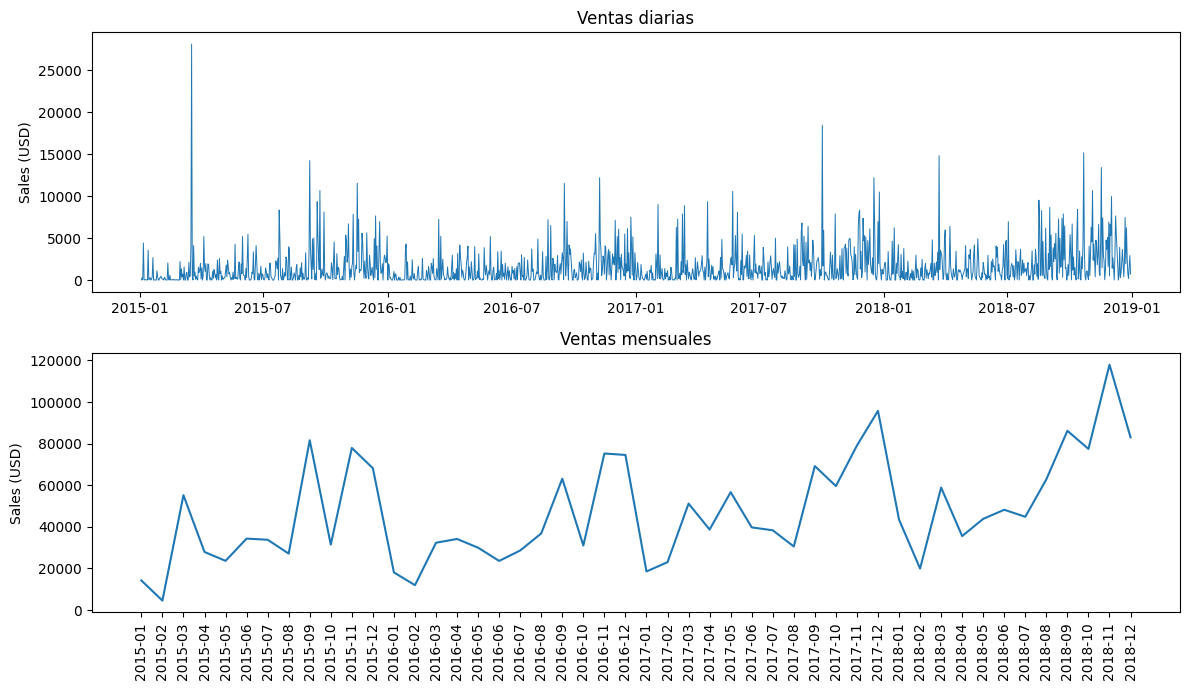

In [6]:
daily = pl.daily_sales(df)
dbs = pl.sql_databases(df, daily)
display(daily.describe(include='all'))

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(daily.date, daily.sales, linewidth=.7)
axes[0].set(title='Ventas diarias', ylabel='Sales (USD)')
mensual = daily.assign(mes=daily.date.dt.to_period('M')).groupby('mes').sales.sum()
axes[1].plot(mensual.index.astype(str), mensual.values)
axes[1].tick_params(axis='x', rotation=90)
axes[1].set(title='Ventas mensuales', ylabel='Sales (USD)')
plt.tight_layout(); plt.show()

In [7]:
for label, path in dbs.items():
    with sqlite3.connect(path) as conn:
        print('\nBASE:', label, '|', path)
        display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))

with sqlite3.connect(dbs['transacciones']) as conn:
    display(pd.read_sql_query(
        'SELECT category, COUNT(*) AS registros, ROUND(SUM(sales),2) AS ventas '
        'FROM ventas GROUP BY category ORDER BY ventas DESC', conn))

with sqlite3.connect(dbs['analitica']) as conn:
    display(pd.read_sql_query(
        'SELECT periodo, ROUND(ventas,2) AS ventas FROM ventas_mensuales '
        'ORDER BY periodo DESC LIMIT 12', conn))


BASE: transacciones | bases_sql/transacciones.sqlite


,name
0,ventas



BASE: analitica | bases_sql/analitica.sqlite


,name
0,ventas_diarias
1,ventas_mensuales



BASE: predicciones | bases_sql/predicciones.sqlite


,name
0,predicciones


,category,registros,ventas
0,Technology,1813,827455.87
1,Furniture,2078,728658.58
2,Office Supplies,5909,705422.33


,periodo,ventas
0,2018-12,83030.39
1,2018-11,117938.15
2,2018-10,77448.13
3,2018-09,86152.89
4,2018-08,62837.85
5,2018-07,44825.10
6,2018-06,48190.73
7,2018-05,43825.98
8,2018-04,35541.91
9,2018-03,58863.41


## PASO 2 — Preparación, pipeline y aumento de datos
Se agregan las ventas a frecuencia diaria, se divide **cronológicamente** la serie (70/15/15), se
normaliza con estadísticas **exclusivas del entrenamiento** y se crean **ventanas deslizantes de
28 días** para predecir el día 29.

**Data augmentation:** ruido gaussiano pequeño (σ = 0,015) **solo en las entradas de
entrenamiento**, nunca en validación/prueba ni en las etiquetas.

In [8]:
bundle = pl.prepare(daily, window=pl.WINDOW)
print('Fechas de corte:', bundle['limits'])
print('Forma de X (muestras, días, variables):', bundle['X'].shape)
for name, mask in bundle['masks'].items():
    print(name, int(mask.sum()), 'muestras')
print('Media y desviación de entrenamiento:', bundle['scaler'].mean_[0], bundle['scaler'].scale_[0])
display(pd.DataFrame(bundle['X'][0, :, 0], columns=['ventas_normalizadas_ventana_1']).head())

Fechas de corte: {'train_end': '2017-10-18', 'val_end': '2018-05-25', 'test_end': '2018-12-30'}
Forma de X (muestras, días, variables): (1430, 28, 1)
train 992 muestras
val 219 muestras
test 219 muestras
Media y desviación de entrenamiento: 1318.7569359803922 2063.7184990564197


,ventas_normalizadas_ventana_1
0,-0.631050
1,-0.499437
2,-0.629553
3,1.496494
4,-0.596786


## PASO 3 — Construcción y entrenamiento de las tres redes neuronales

### 3.1 CNN (Conv1D)
Dos bloques convolucionales 1D (16 y 32 filtros, kernel 5) con `BatchNorm`, `ReLU` y `Dropout`,
seguidos de *global average pooling* y una cabeza densa.

### 3.2 Secuencial (LSTM + GRU)
Capa `LSTM` (32 unidades) seguida de una capa `GRU` (32 unidades) y una cabeza densa.

### 3.3 Transformer (atención)
Proyección lineal a `d_model=32`, codificación posicional senoidal, 2 capas de
`TransformerEncoder` (4 cabezas de atención) y promedio temporal antes de la cabeza densa.

**Entrenamiento (común a las tres):** Adam, pérdida Huber, recorte de gradientes, *early stopping*
y `ReduceLROnPlateau`.

Entrenando arquitectura: CNN (Conv1D)
Conv1DForecast(
  (conv): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.15, inplace=False)
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
  )
  (pool): AdaptiveAvgPool1d(output_size=1)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Parámetros entrenables: 3329


,epoch,train_loss,val_loss
24,25,0.272321,0.373968
25,26,0.272415,0.374600
26,27,0.271317,0.374616


Entrenando arquitectura: Secuencial (LSTM+GRU)
SecuencialForecast(
  (lstm): LSTM(1, 32, batch_first=True)
  (gru): GRU(32, 32, batch_first=True)
  (drop): Dropout(p=0.12, inplace=False)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Parámetros entrenables: 11361


,epoch,train_loss,val_loss
10,11,0.275092,0.376337
11,12,0.275235,0.376764
12,13,0.274847,0.376843


Entrenando arquitectura: Transformer (atencion)
TransformerForecast(
  (proyeccion): Linear(in_features=1, out_features=32, bias=True)
  (pos): PositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=64, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=64, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_feat

,epoch,train_loss,val_loss
32,33,0.263447,0.354355
33,34,0.262186,0.368210
34,35,0.262294,0.350461


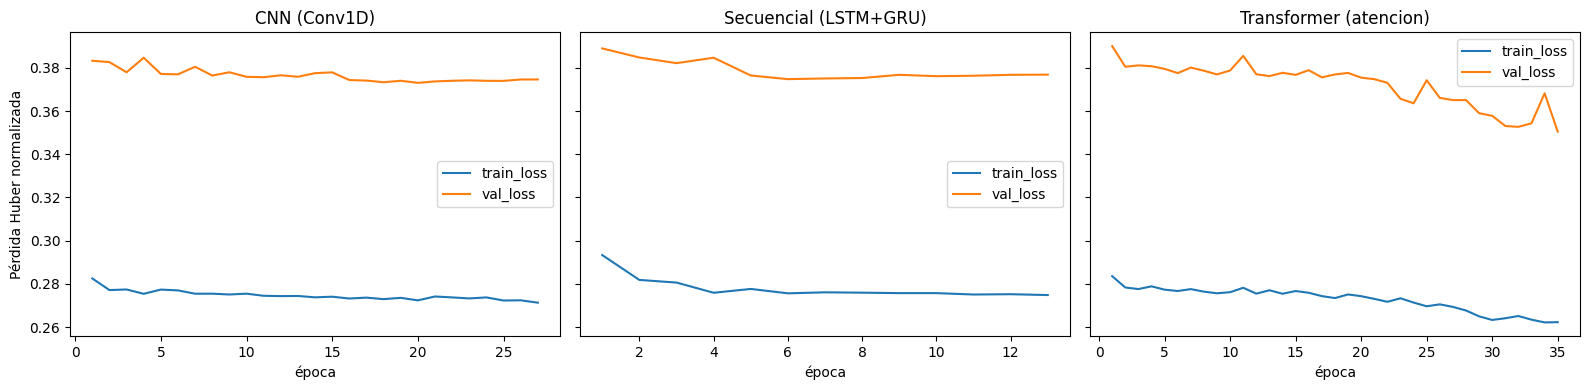

In [9]:
import torch
resultados = {}
for tipo in pl.MODELOS:
    print('='*70)
    print('Entrenando arquitectura:', pl.NOMBRES_MODELOS[tipo])
    modelo = pl.construir_modelo(tipo, window=pl.WINDOW)
    print(modelo)
    n_param = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print('Parámetros entrenables:', n_param)
    modelo, historia = pl.train_model(bundle, tipo=tipo, epochs=35, patience=7, augment=True, model=modelo)
    resultados[tipo] = {'modelo': modelo, 'historia': historia, 'n_parametros': n_param}
    display(historia.tail(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, tipo in zip(axes, pl.MODELOS):
    h = resultados[tipo]['historia']
    ax.plot(h.epoch, h.train_loss, label='train_loss')
    ax.plot(h.epoch, h.val_loss, label='val_loss')
    ax.set_title(pl.NOMBRES_MODELOS[tipo]); ax.set_xlabel('época'); ax.legend()
axes[0].set_ylabel('Pérdida Huber normalizada')
plt.tight_layout(); plt.show()

## PASO 4 — Evaluación y métricas

**Métricas principales (regresión):** MAE, RMSE, sMAPE y R², comparadas con una referencia
ingenua semanal (ventas del mismo día de la semana anterior).

**Métricas auxiliares (clasificación):** venta alta = ventas ≥ percentil 75 del entrenamiento;
reales y predichos se binarizan con el mismo umbral para reportar Accuracy/F1/matriz de confusión
(ninguno de los tres modelos es un clasificador entrenado específicamente).

In [10]:
comparacion_filas = []
for tipo in pl.MODELOS:
    modelo = resultados[tipo]['modelo']
    metrics, pred, umbral = pl.evaluate(modelo, bundle)
    pronostico = pl.forecast_next(modelo, bundle)
    resultados[tipo].update({'metrics': metrics, 'pred': pred, 'umbral': umbral, 'pronostico': pronostico})

    print('\n' + '='*70)
    print(pl.NOMBRES_MODELOS[tipo], '| Umbral venta alta:', round(umbral, 2),
          '| Pronóstico día siguiente:', round(pronostico, 2))
    tabla = pd.DataFrame(metrics).T[['n','MAE','MAE_baseline_semanal','RMSE','sMAPE','R2',
                                      'Accuracy_alta_venta','F1_alta_venta']]
    display(tabla)
    comparacion_filas.append({
        'arquitectura': pl.NOMBRES_MODELOS[tipo],
        'MAE_test': metrics['test']['MAE'], 'RMSE_test': metrics['test']['RMSE'],
        'sMAPE_test': metrics['test']['sMAPE'], 'R2_test': metrics['test']['R2'],
        'F1_alta_venta_test': metrics['test']['F1_alta_venta'],
        'parametros': resultados[tipo]['n_parametros'],
    })

comparacion = pd.DataFrame(comparacion_filas).set_index('arquitectura')
print('\nCOMPARACIÓN FINAL DE LAS TRES ARQUITECTURAS (partición de prueba):')
display(comparacion.style.format({'MAE_test':'{:.1f}','RMSE_test':'{:.1f}','sMAPE_test':'{:.1f}',
                                   'R2_test':'{:.3f}','F1_alta_venta_test':'{:.3f}'}))


CNN (Conv1D) | Umbral venta alta: 1799.39 | Pronóstico día siguiente: 1672.86


,n,MAE,MAE_baseline_semanal,RMSE,sMAPE,R2,Accuracy_alta_venta,F1_alta_venta
train,992,1176.934692,1487.0896,2059.141326,106.580185,0.019679,0.75,0.0
val,219,1447.063477,1605.885742,2248.300914,97.05381,-0.002978,0.666667,0.141176
test,219,1808.511475,2297.819336,2746.232055,92.370674,-0.136699,0.538813,0.0



Secuencial (LSTM+GRU) | Umbral venta alta: 1799.39 | Pronóstico día siguiente: 1540.22


,n,MAE,MAE_baseline_semanal,RMSE,sMAPE,R2,Accuracy_alta_venta,F1_alta_venta
train,992,1209.289062,1487.0896,2062.237135,107.264793,0.016729,0.75,0.0
val,219,1450.743896,1605.885742,2264.050905,97.474228,-0.017079,0.6621,0.0
test,219,1815.991211,2297.819336,2726.112525,92.368378,-0.120105,0.538813,0.0



Transformer (atencion) | Umbral venta alta: 1799.39 | Pronóstico día siguiente: 2008.4


,n,MAE,MAE_baseline_semanal,RMSE,sMAPE,R2,Accuracy_alta_venta,F1_alta_venta
train,992,1125.207397,1487.0896,2010.112248,105.792793,0.065807,0.75,0.314917
val,219,1377.847656,1605.885742,2163.57586,96.310005,0.07119,0.707763,0.483871
test,219,1770.60437,2297.819336,2642.943246,90.988678,-0.052802,0.584475,0.497238



COMPARACIÓN FINAL DE LAS TRES ARQUITECTURAS (partición de prueba):


,MAE_test,RMSE_test,sMAPE_test,R2_test,F1_alta_venta_test,parametros
arquitectura,,,,,,
CNN (Conv1D),1808.5,2746.2,92.4,-0.137,0.000,3329
Secuencial (LSTM+GRU),1816.0,2726.1,92.4,-0.120,0.000,11361
Transformer (atencion),1770.6,2642.9,91.0,-0.053,0.497,17697


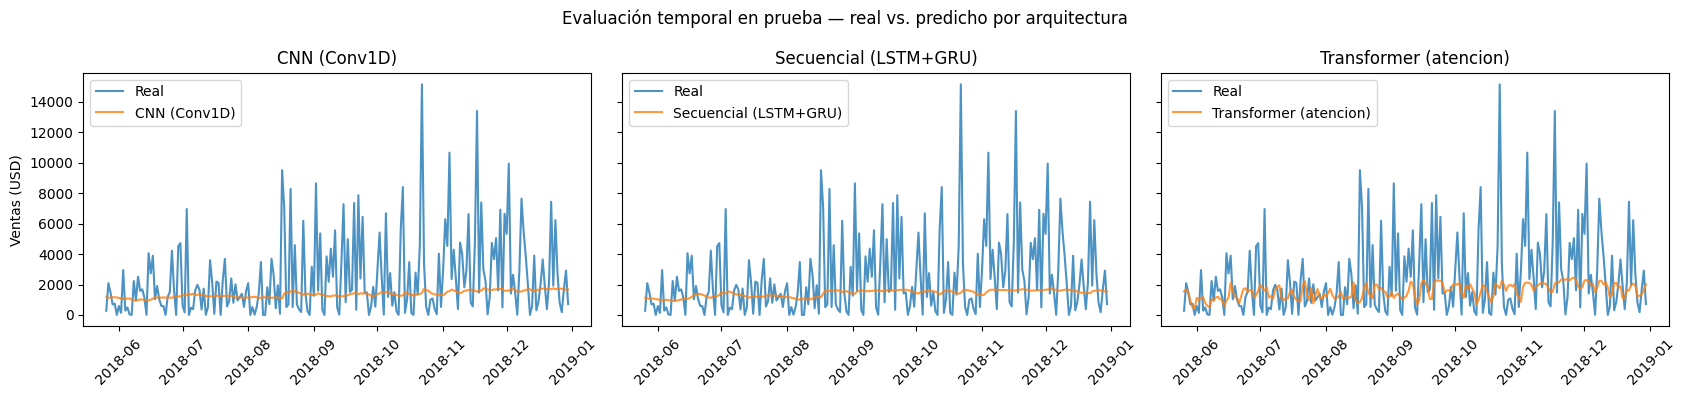

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, tipo in zip(axes, pl.MODELOS):
    test = resultados[tipo]['pred']
    test = test.loc[test.particion == 'test'].copy()
    ax.plot(pd.to_datetime(test.fecha), test.real, label='Real', alpha=.8)
    ax.plot(pd.to_datetime(test.fecha), test.prediccion, label=pl.NOMBRES_MODELOS[tipo], alpha=.8)
    ax.legend(); ax.set_title(pl.NOMBRES_MODELOS[tipo]); ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Ventas (USD)')
fig.suptitle('Evaluación temporal en prueba — real vs. predicho por arquitectura')
plt.tight_layout(); plt.show()

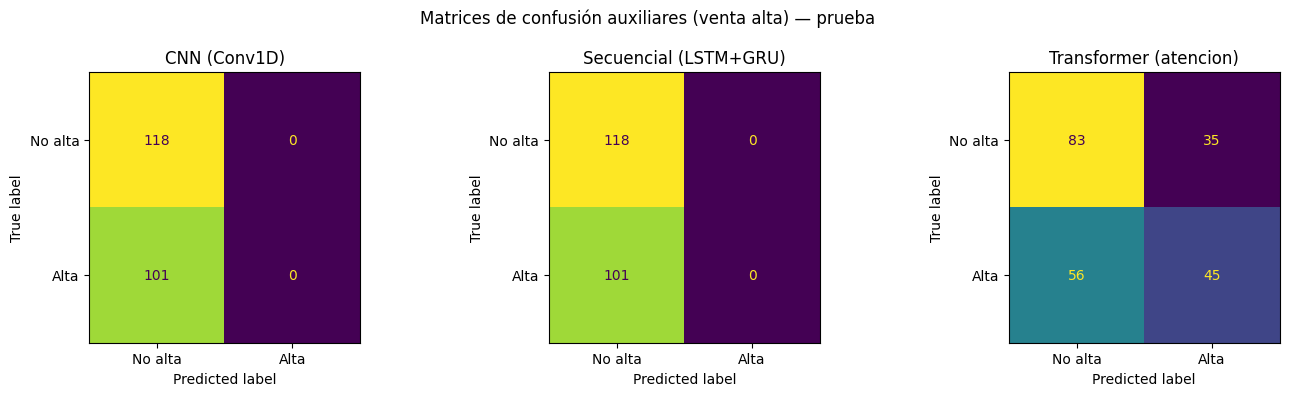

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, tipo in zip(axes, pl.MODELOS):
    cm = np.array(resultados[tipo]['metrics']['test']['confusion'])
    ConfusionMatrixDisplay(cm, display_labels=['No alta', 'Alta']).plot(ax=ax, colorbar=False)
    ax.set_title(pl.NOMBRES_MODELOS[tipo])
plt.suptitle('Matrices de confusión auxiliares (venta alta) — prueba')
plt.tight_layout(); plt.show()

## PASO 5 — Persistencia, póster y despliegue en Streamlit + ngrok

**Qué se hace:** se regenera el pipeline completo (`pipeline.run`) y se persisten, para **cada una
de las tres arquitecturas**: pesos `.pt`, métricas `.json`, historial `.csv`, predicciones `.csv`
y las tres bases SQLite, todas dentro de `pesos/` y `bases_sql/` (rutas que `app.py` lee
directamente, sin necesidad de ajustar nada a mano).

In [13]:
# Reentrena y persiste artefactos de forma íntegra para las tres arquitecturas.
# Puede tardar algunos minutos según el hardware disponible.
info = pl.run(epochs=35)
display(info['comparacion'])
print('Bases SQL generadas:', info['sql_bases'])
for tipo in pl.MODELOS:
    print(pl.NOMBRES_MODELOS[tipo], '-> pronóstico día siguiente:',
          round(info['resultados'][tipo]['pronostico_dia_siguiente'], 2))

,MAE_test,RMSE_test,sMAPE_test,R2_test,F1_alta_venta_test,parametros
cnn,1802.055664,2729.768122,91.971954,-0.123111,0.000000,3329.0
rnn,1807.582886,2693.440272,91.731842,-0.093417,0.304348,11361.0
transformer,1806.225586,2697.614131,90.851112,-0.096808,0.000000,17697.0


Bases SQL generadas: ['bases_sql/transacciones.sqlite', 'bases_sql/analitica.sqlite', 'bases_sql/predicciones.sqlite']
CNN (Conv1D) -> pronóstico día siguiente: 1689.85
Secuencial (LSTM+GRU) -> pronóstico día siguiente: 1627.14
Transformer (atencion) -> pronóstico día siguiente: 1729.55


In [14]:
# Generación del póster PDF (Entregable oficial 4.2)
try:
    from poster import make_poster
except ModuleNotFoundError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "reportlab"], check=True)
    from poster import make_poster

poster_path = ROOT / 'docs/Poster_ACA2_Ventas.pdf'
poster_path.parent.mkdir(exist_ok=True)
make_poster(info, integrantes='Integrantes: completar antes de entregar',
            app_url='URL pública: se genera en la celda de ngrok de abajo',
            output=poster_path)
print('Póster PDF:', poster_path)
print('Aplicación Streamlit:', ROOT / 'app.py')

Póster PDF: /content/docs/Poster_ACA2_Ventas.pdf
Aplicación Streamlit: /content/app.py


### CSV de prueba para la pestaña "Pronóstico interactivo"
La siguiente celda genera `ventas_prueba.csv`, una serie simulada de 60 días con una columna
`sales` (la que `app.py` espera). Sirve para comprobar, dentro de la app, el botón de **subir CSV
propio** sin tener que usar el dataset completo. No requiere Google Colab: se guarda en la carpeta
de trabajo y, si está en Colab, se ofrece además la descarga al equipo.

In [15]:
import numpy as np

np.random.seed(42)
dias_prueba = 60
fechas_prueba = pd.date_range(end=pd.Timestamp.today().normalize(), periods=dias_prueba, freq='D')
tendencia = np.linspace(900, 1600, dias_prueba)
estacionalidad = 300 * np.sin(np.linspace(0, 6*np.pi, dias_prueba))
ruido = np.random.normal(0, 150, dias_prueba)
ventas_simuladas = np.clip(tendencia + estacionalidad + ruido, 50, None)

ventas_prueba = pd.DataFrame({'date': fechas_prueba.strftime('%Y-%m-%d'),
                               'sales': np.round(ventas_simuladas, 2)})
ventas_prueba.to_csv('ventas_prueba.csv', index=False)
print('Archivo de prueba generado: ventas_prueba.csv (', len(ventas_prueba), 'días )')
display(ventas_prueba.head())

try:
    from google.colab import files
    files.download('ventas_prueba.csv')
except Exception:
    pass  # fuera de Colab simplemente queda guardado en la carpeta de trabajo

Archivo de prueba generado: ventas_prueba.csv ( 60 días )


,date,sales
0,2026-09-06,974.51
1,2026-09-07,985.35
2,2026-09-08,1199.79
3,2026-09-09,1409.54
4,2026-09-10,1199.56


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Despliegue de la app: local, red local y URL pública con ngrok
La celda siguiente:
1. Verifica que `pesos/` y `bases_sql/` ya existan (si no, avisa y se detiene en vez de fallar
   con un error confuso).
2. Libera el puerto 8501 de cualquier proceso anterior.
3. Lanza Streamlit en segundo plano y **espera a que realmente responda** antes de abrir el túnel
   (la causa más común de "ngrok sin errores pero no abre nada" es intentar conectar el túnel
   antes de que Streamlit haya terminado de arrancar).
4. Abre el túnel ngrok con el token ya vinculado y **imprime la URL pública**.

**Formas de acceso una vez ejecutada esta celda:**
- Local (dentro de Colab no aplica): `http://localhost:8501`
- Red local: `http://IP_DE_ESTE_EQUIPO:8501` (solo si corre en su propio computador, no en Colab)
- **URL pública (ngrok):** la que imprime la celda, tipo `https://xxxx.ngrok-free.app` — es la que
  debe compartir, pegar en el póster y mostrar en el video de sustentación.

In [29]:
import os, sys, time, subprocess, urllib.request
from pathlib import Path as _P

PUERTO = 8501
NGROK_AUTHTOKEN = "3KypTULuObh7uPdmRp9VBRieQtq_6jVUhxkgGunkseDsHhLyb"

if not (Path('pesos').exists() and Path('bases_sql').exists()):
    raise RuntimeError("Faltan 'pesos/' y/o 'bases_sql/'. Ejecute primero la celda de pl.run(epochs=35).")

for paquete, modulo in [("streamlit", "streamlit"), ("pyngrok", "pyngrok")]:
    try:
        __import__(modulo)
    except ImportError:
        print(f"Instalando {paquete}...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)
from pyngrok import ngrok

config_dir = _P.home() / ".streamlit"
config_dir.mkdir(exist_ok=True)
(config_dir / "credentials.toml").write_text('[general]\nemail = ""\n')
(config_dir / "config.toml").write_text(
    "[server]\nheadless = true\nenableCORS = false\nenableXsrfSetup = false\n"
    "[browser]\ngatherUsageStats = false\n"
)

os.system(f"fuser -k {PUERTO}/tcp >/dev/null 2>&1")
try:
    ngrok.kill()
except Exception:
    pass
os.system("pkill -f 'streamlit run app.py' >/dev/null 2>&1")
time.sleep(2)

log_path = _P("streamlit.log")
proceso_streamlit = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py",
     "--server.address", "0.0.0.0", "--server.port", str(PUERTO),
     "--server.headless", "true"],
    stdin=subprocess.DEVNULL,
    stdout=open(log_path, "w"), stderr=subprocess.STDOUT,
)
print(f"Streamlit iniciado (PID {proceso_streamlit.pid}). Esperando a que responda en el puerto {PUERTO}...")

listo = False
for intento in range(30):
    time.sleep(2)
    try:
        urllib.request.urlopen(f"http://localhost:{PUERTO}", timeout=2)
        listo = True
        break
    except Exception:
        if proceso_streamlit.poll() is not None:
            print("El proceso de Streamlit terminó inesperadamente. Log:")
            print(log_path.read_text(encoding="utf-8", errors="ignore"))
            break
        if intento in (4, 9, 14, 19, 24):
            print(f"  ...sigue esperando ({(intento+1)*2}s)")

if not listo:
    print("\nADVERTENCIA: Streamlit no respondió a tiempo. Log completo:")
    print(log_path.read_text(encoding="utf-8", errors="ignore"))
else:
    print("Streamlit está arriba. Abriendo túnel ngrok...")

    # El token ya puede estar guardado de una corrida anterior: pyngrok a veces trata ese
    # aviso (no un error real) como excepción, así que se ignora.
    try:
        ngrok.set_auth_token(NGROK_AUTHTOKEN)
    except Exception:
        pass

    tunel = None
    for intento in range(5):
        try:
            tunel = ngrok.connect(PUERTO, "http")
            break
        except Exception as e:
            print(f"Intento {intento+1}/5 falló ({e}); reintentando en 8s...")
            try:
                ngrok.kill()
            except Exception:
                pass
            time.sleep(8)

    if tunel:
        print("=" * 70)
        print(f"URL PÚBLICA (ngrok): {tunel.public_url}")
        print("=" * 70)
        print("Copie la URL pública de arriba: es la que debe usar en el póster y en el video.")
    else:
        print("No se pudo abrir el túnel tras 5 intentos: el endpoint anterior sigue activo en otra "
              "sesión. Deténlo en https://dashboard.ngrok.com/endpoints y vuelve a ejecutar esta celda.")

Streamlit iniciado (PID 8821). Esperando a que responda en el puerto 8501...
Streamlit está arriba. Abriendo túnel ngrok...
URL PÚBLICA (ngrok): https://pesky-bonanza-charger.ngrok-free.dev
Copie la URL pública de arriba: es la que debe usar en el póster y en el video.


### Para detener el despliegue
Ejecute esta celda cuando termine de usar o sustentar la app, para liberar el puerto y cerrar el
túnel:

## Conclusiones, límites y guion de sustentación

1. Se cumplió el flujo completo exigido por el ACA N.º 2: EDA → gestión SQL (3 bases) →
   ingeniería de secuencias con aumento de datos → **tres arquitecturas de red neuronal (CNN,
   Secuencial LSTM+GRU, Transformer)** → métricas comparativas → despliegue Streamlit con URL
   pública (ngrok) → póster PDF.
2. La comparación entre arquitecturas y frente a un baseline ingenuo semanal evita atribuir
   capacidad predictiva por el solo hecho de usar Deep Learning.
3. El conjunto es histórico (2015–2018), sin variables exógenas (clima, promociones, inventario,
   feriados); ninguna de las tres arquitecturas debe desplegarse como sistema comercial real sin
   ampliar las variables de entrada.
4. El póster y la app deben completarse con los nombres reales del equipo y la URL pública real
   generada por la celda de ngrok antes de la entrega final.
5. Un documento de **guion de sustentación** (sin video, solo texto para exponer) se entrega por
   separado: `Sustentacion_ACA2.md`.

**Nota de seguridad:** el token de ngrok queda escrito dentro de este notebook para que el
despliegue funcione sin pasos adicionales. Si va a compartir el notebook públicamente (por
ejemplo, subirlo a un repositorio público), revóquelo y genere uno nuevo después en
https://dashboard.ngrok.com/tunnels/authtokens.

### Referencias (APA 7)
Corporación Unificada Nacional de Educación Superior. (s. f.). *ACA n.º 2: Aprendizaje automático*
[Guía académica].

Luque, G. (2021). *Sales Forecasting - Retail Superstore* [Conjunto de datos]. Kaggle.
https://www.kaggle.com/datasets/rohitsahoo/sales-forecasting

PyTorch. (s. f.). *nn.Conv1d*. https://pytorch.org/docs/stable/generated/torch.nn.Conv1d.html

PyTorch. (s. f.). *nn.TransformerEncoder*. https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html

Streamlit. (s. f.). *Streamlit documentation*. https://docs.streamlit.io/

ngrok Inc. (s. f.). *pyngrok documentation*. https://pyngrok.readthedocs.io/

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., &
Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing
Systems*, 30.

**Origen de los datos:** `train.csv`, archivo facilitado para la actividad; autoría y licencia no
especificadas por el docente.